# 03 — Feature Engineering

## Restaurant Customer Intelligence

This notebook prepares customer-level features for subsequent segmentation and
machine-learning analysis.

Feature engineering is based only on information supported by the available
dataset. Variables are not assigned temporal or behavioral meanings that cannot
be inferred from the source data.

### Objectives

1. Prepare numerical and categorical customer features.
2. Create interpretable demographic and behavioral variables.
3. Evaluate relationships between spending, income, visit frequency, Premium
   membership, and food preferences.
4. Avoid redundant or unsupported derived variables.
5. Produce a feature dataset suitable for customer segmentation.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [2]:
DATA_PATH = Path("../data/processed/customers_clean.csv")

df = pd.read_csv(DATA_PATH)

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

df.head()

Rows: 30,000
Columns: 13


,id_persona,edad,genero,ciudad_residencia,estrato_socioeconomico,frecuencia_visita,promedio_gasto_comida,ocio,consume_licor,preferencias_alimenticias,membresia_premium,tipo_de_pago_mas_usado,ingresos_mensuales
0,2550327378,31.00,Masculino,Miami,Alto,6.00,67.51,Sí,No,Vegetariano,Sí,Efectivo,6425
1,9446112038,40.00,Femenino,Denver,Medio,2.00,44.92,Sí,Sí,Mariscos,No,Efectivo,2374
2,3098363243,62.00,Femenino,Denver,Bajo,2.00,9.24,Sí,Sí,Vegetariano,No,Efectivo,1110
3,4013002847,41.00,Masculino,Boston,Alto,5.00,30.74,Sí,Sí,Carnes,Sí,Tarjeta,6931
4,7372911048,49.00,Femenino,San Diego,Bajo,0.00,0.00,No,No,Carnes,No,Tarjeta,1350


In [3]:
feature_inventory = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True)
})

feature_inventory

,dtype,missing,missing_pct,unique_values
id_persona,int64,0,0.00,30000
edad,float64,308,1.03,63
genero,str,0,0.00,2
ciudad_residencia,str,0,0.00,10
estrato_socioeconomico,str,0,0.00,4
frecuencia_visita,float64,1547,5.16,11
promedio_gasto_comida,float64,145,0.48,8186
ocio,str,0,0.00,2
consume_licor,str,0,0.00,2
preferencias_alimenticias,str,1403,4.68,6


In [4]:
identifier_features = [
    "id_persona"
]

numeric_features = [
    "edad",
    "frecuencia_visita",
    "promedio_gasto_comida",
    "ingresos_mensuales"
]

categorical_features = [
    "genero",
    "ciudad_residencia",
    "estrato_socioeconomico",
    "ocio",
    "consume_licor",
    "preferencias_alimenticias",
    "membresia_premium",
    "tipo_de_pago_mas_usado"
]

print("Identifier:", identifier_features)
print("Numeric:", numeric_features)
print("Categorical:", categorical_features)

Identifier: ['id_persona']
Numeric: ['edad', 'frecuencia_visita', 'promedio_gasto_comida', 'ingresos_mensuales']
Categorical: ['genero', 'ciudad_residencia', 'estrato_socioeconomico', 'ocio', 'consume_licor', 'preferencias_alimenticias', 'membresia_premium', 'tipo_de_pago_mas_usado']


In [5]:
df_features = df.copy()

age_bins = [18, 25, 35, 45, 55, 65, 81]

age_labels = [
    "18-24",
    "25-34",
    "35-44",
    "45-54",
    "55-64",
    "65-80"
]

df_features["grupo_edad"] = pd.cut(
    df_features["edad"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

df_features["grupo_edad"].value_counts(
    sort=False,
    dropna=False
)

grupo_edad
18-24    3261
25-34    4791
35-44    4746
45-54    4758
55-64    4664
65-80    7472
NaN       308
Name: count, dtype: int64

### Feature: age group

Valid customer ages were grouped into interpretable life-stage ranges while
preserving the original numerical `edad` variable.

The resulting groups show a reasonably distributed customer population, although
customers aged 65–80 represent the largest group.

The 308 records with missing age remain unassigned rather than being artificially
imputed.

**Decision:** the interpretable age ranges are retained instead of using
quantile-based groups, since equal-sized age groups would be less meaningful for
business interpretation.

In [6]:
df_features["premium_flag"] = (
    df_features["membresia_premium"]
    .map({
        "Sí": 1,
        "No": 0
    })
)

df_features[
    ["membresia_premium", "premium_flag"]
].value_counts()

membresia_premium  premium_flag
No                 0               17155
Sí                 1               12845
Name: count, dtype: int64

In [7]:
df_features["spending_income_ratio"] = (
    df_features["promedio_gasto_comida"] /
    df_features["ingresos_mensuales"]
)

df_features["spending_income_ratio"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

count   29,855.00
mean         0.01
std          0.00
min          0.00
25%          0.00
50%          0.01
75%          0.01
90%          0.01
95%          0.02
99%          0.02
max          0.03
Name: spending_income_ratio, dtype: float64

In [8]:
df_features[
    [
        "promedio_gasto_comida",
        "ingresos_mensuales",
        "spending_income_ratio"
    ]
].corr().round(3)

,promedio_gasto_comida,ingresos_mensuales,spending_income_ratio
promedio_gasto_comida,1.00,0.64,0.25
ingresos_mensuales,0.64,1.00,-0.37
spending_income_ratio,0.25,-0.37,1.00


### Feature: spending-to-income ratio

A `spending_income_ratio` feature was created as the ratio between average food
spending and monthly income.

This variable is interpreted as a relative spending-intensity indicator and not
as the percentage of monthly income allocated to restaurants, since the dataset
does not specify the time period represented by `promedio_gasto_comida`.

The feature provides information that is not fully captured by either spending
or income independently:

- Correlation with food spending: 0.251
- Correlation with monthly income: -0.372
- Food spending and income themselves show a stronger correlation of 0.637.

**Decision:** `spending_income_ratio` is retained as a candidate segmentation
feature because it adds a distinct relative-spending dimension.

In [9]:
df_features["frecuencia_visita"].describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
)

count   28,453.00
mean         4.27
std          2.28
min          0.00
10%          1.00
25%          3.00
50%          4.00
75%          6.00
90%          7.00
max         10.00
Name: frecuencia_visita, dtype: float64

In [10]:
frequency_distribution = (
    df_features["frecuencia_visita"]
    .value_counts(dropna=False)
    .sort_index()
)

frequency_distribution

frecuencia_visita
0.00     1463
1.00     1459
2.00     3659
3.00     3697
4.00     5042
5.00     5932
6.00     3746
7.00      878
8.00      862
9.00      839
10.00     876
NaN      1547
Name: count, dtype: int64

In [11]:
frequency_profile = (
    df_features.groupby(
        "frecuencia_visita",
        dropna=False
    )
    .agg(
        customers=("id_persona", "count"),
        avg_spending=("promedio_gasto_comida", "mean"),
        avg_income=("ingresos_mensuales", "mean"),
        premium_pct=("premium_flag", "mean")
    )
)

frequency_profile["premium_pct"] *= 100

frequency_profile.round(2)

,customers,avg_spending,avg_income,premium_pct
frecuencia_visita,,,,
0.00,1463,0.00,"1,201.33",0.34
1.00,1459,11.70,"1,196.90",0.55
2.00,3659,19.23,"2,012.22",8.69
3.00,3697,18.99,"2,006.60",8.76
4.00,5042,31.94,"4,629.48",44.82
5.00,5932,37.22,"5,990.64",53.10
6.00,3746,43.71,"7,857.78",76.08
7.00,878,63.77,"13,600.35",94.99
8.00,862,65.77,"13,555.41",96.17


### Finding: visit frequency and customer value

Visit frequency shows a strong relationship with several customer-value
variables.

Customers with higher visit frequency generally present higher food spending,
higher monthly income, and substantially higher Premium membership penetration.

For example, customers with zero recorded visits have near-zero Premium
penetration and zero average food spending, while customers with visit
frequencies between 7 and 10 show Premium penetration above 93% and considerably
higher income and spending levels.

This strong structure suggests that several behavioral and socioeconomic
variables may contain overlapping information.

**Modeling implication:** correlated features will be evaluated carefully before
customer segmentation. Clustering results should not be interpreted as
independent behavioral discoveries if they mainly reproduce relationships already
embedded in the source data.

In [12]:
candidate_numeric_features = [
    "edad",
    "frecuencia_visita",
    "promedio_gasto_comida",
    "ingresos_mensuales",
    "premium_flag",
    "spending_income_ratio"
]

feature_correlations = (
    df_features[candidate_numeric_features]
    .corr()
    .round(3)
)

feature_correlations

,edad,frecuencia_visita,promedio_gasto_comida,ingresos_mensuales,premium_flag,spending_income_ratio
edad,1.00,-0.02,-0.00,-0.01,-0.01,-0.00
frecuencia_visita,-0.02,1.00,0.61,0.78,0.60,-0.14
promedio_gasto_comida,-0.00,0.61,1.00,0.64,0.49,0.25
ingresos_mensuales,-0.01,0.78,0.64,1.00,0.66,-0.37
premium_flag,-0.01,0.60,0.49,0.66,1.00,-0.23
spending_income_ratio,-0.00,-0.14,0.25,-0.37,-0.23,1.00


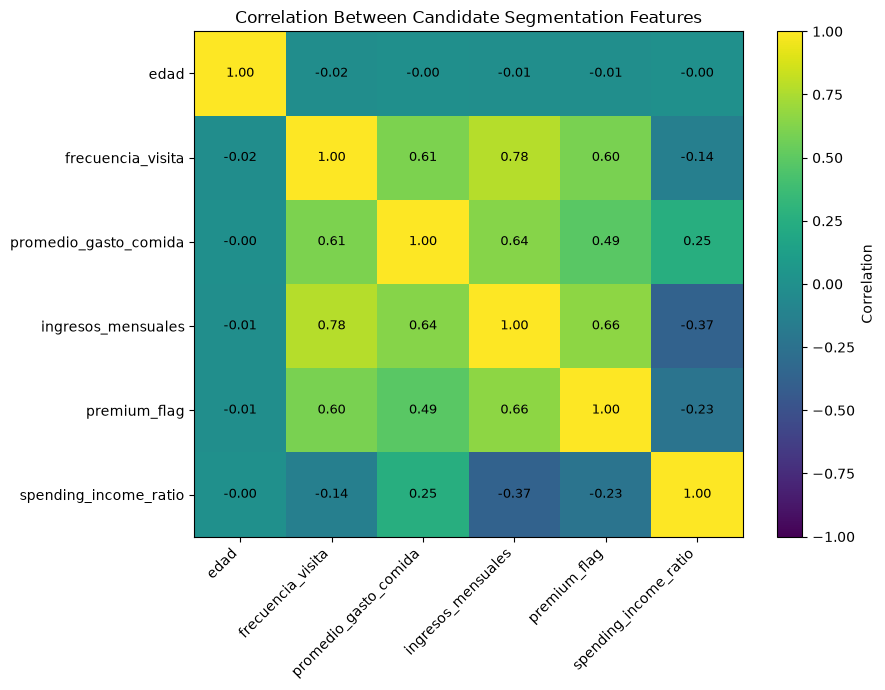

In [13]:
plt.figure(figsize=(9, 7))

plt.imshow(
    feature_correlations,
    aspect="auto",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(feature_correlations.columns)),
    feature_correlations.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(feature_correlations.index)),
    feature_correlations.index
)

for i in range(len(feature_correlations)):
    for j in range(len(feature_correlations.columns)):
        plt.text(
            j,
            i,
            f"{feature_correlations.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=9
        )

plt.title("Correlation Between Candidate Segmentation Features")
plt.tight_layout()
plt.show()

### Finding: correlation between candidate features

Customer-value variables show moderate to strong relationships, confirming the
structure observed in the visit-frequency analysis.

The strongest relationship is between visit frequency and monthly income
(r = 0.78). Other notable correlations include:

- Monthly income and Premium membership: 0.66
- Monthly income and food spending: 0.64
- Visit frequency and food spending: 0.61
- Visit frequency and Premium membership: 0.60

None of these relationships reaches a level that requires automatic feature
removal, but they indicate that customer value is represented through several
related variables.

Age is almost completely independent from the other numerical features, making
it a potentially useful demographic dimension.

The spending-to-income ratio also captures a different pattern and remains a
candidate feature for segmentation.

**Decision:** feature redundancy will be evaluated empirically during clustering
rather than removing variables based only on pairwise correlation.

In [14]:
segmentation_numeric_features = [
    "edad",
    "frecuencia_visita",
    "promedio_gasto_comida",
    "ingresos_mensuales",
    "premium_flag",
    "spending_income_ratio"
]

segmentation_numeric_features

['edad',
 'frecuencia_visita',
 'promedio_gasto_comida',
 'ingresos_mensuales',
 'premium_flag',
 'spending_income_ratio']

In [15]:
socioeconomic_profile = (
    df_features.groupby(
        "estrato_socioeconomico",
        observed=True
    )
    .agg(
        customers=("id_persona", "count"),
        avg_income=("ingresos_mensuales", "mean"),
        median_income=("ingresos_mensuales", "median"),
        avg_spending=("promedio_gasto_comida", "mean"),
        avg_frequency=("frecuencia_visita", "mean"),
        premium_pct=("premium_flag", "mean")
    )
)

socioeconomic_profile["premium_pct"] *= 100

socioeconomic_profile.round(2)

,customers,avg_income,median_income,avg_spending,avg_frequency,premium_pct
estrato_socioeconomico,,,,,,
Alto,9038,"6,232.17","6,210.00",38.14,5.01,69.71
Bajo,6161,"1,197.81","1,199.00",8.88,1.50,0.44
Medio,9325,"2,544.76","2,540.00",24.24,3.50,13.95
Muy Alto,5476,"13,560.40","13,572.50",64.41,7.48,95.27


### Finding: socioeconomic segment as a descriptive variable

Socioeconomic segment shows a strong and ordered relationship with customer
income, spending, visit frequency, and Premium membership.

Customers classified as `Muy Alto` have substantially higher income, spending,
visit frequency, and Premium penetration than customers classified as `Alto`,
`Medio`, or `Bajo`.

This indicates that `estrato_socioeconomico` contains substantial information
already represented by the numerical customer-value features.

**Decision:** `estrato_socioeconomico` will not be used to generate customer
clusters. It will instead be retained as a descriptive variable to interpret
and validate the resulting segments.

This avoids giving the same underlying socioeconomic dimension excessive weight
during clustering.

In [16]:
segmentation_features = [
    "edad",
    "frecuencia_visita",
    "promedio_gasto_comida",
    "ingresos_mensuales",
    "premium_flag",
    "spending_income_ratio"
]

interpretation_features = [
    "grupo_edad",
    "genero",
    "ciudad_residencia",
    "estrato_socioeconomico",
    "ocio",
    "consume_licor",
    "preferencias_alimenticias",
    "membresia_premium",
    "tipo_de_pago_mas_usado"
]

print("Segmentation features:")
for feature in segmentation_features:
    print(f"  - {feature}")

print("\nInterpretation features:")
for feature in interpretation_features:
    print(f"  - {feature}")

Segmentation features:
  - edad
  - frecuencia_visita
  - promedio_gasto_comida
  - ingresos_mensuales
  - premium_flag
  - spending_income_ratio

Interpretation features:
  - grupo_edad
  - genero
  - ciudad_residencia
  - estrato_socioeconomico
  - ocio
  - consume_licor
  - preferencias_alimenticias
  - membresia_premium
  - tipo_de_pago_mas_usado


In [17]:
segmentation_missing = pd.DataFrame({
    "missing": df_features[segmentation_features].isna().sum(),
    "missing_pct": (
        df_features[segmentation_features].isna().mean() * 100
    ).round(2)
})

segmentation_missing

,missing,missing_pct
edad,308,1.03
frecuencia_visita,1547,5.16
promedio_gasto_comida,145,0.48
ingresos_mensuales,0,0.00
premium_flag,0,0.00
spending_income_ratio,145,0.48


In [18]:
complete_segmentation_rows = (
    df_features[segmentation_features]
    .dropna()
    .shape[0]
)

print(f"Complete rows: {complete_segmentation_rows:,}")
print(
    f"Complete dataset: "
    f"{complete_segmentation_rows / len(df_features) * 100:.2f}%"
)

Complete rows: 28,024
Complete dataset: 93.41%


### Missing values and modeling strategy

The candidate segmentation features contain a limited amount of missing data.

A complete-case approach would retain 28,024 of the 30,000 customers (93.41%)
and exclude 1,976 records (6.59%).

Missing visit frequency values require particular care because they originate
from invalid `-3` values identified during data-quality analysis. They cannot
be interpreted as zero visits.

**Decision:** missing values are preserved in the feature dataset. Their
treatment will be incorporated into the preprocessing pipeline in the customer
segmentation stage, allowing alternative strategies to be evaluated without
permanently modifying the analytical dataset.

In [19]:
print(f"Original columns: {df.shape[1]}")
print(f"Feature dataset columns: {df_features.shape[1]}")

new_features = [
    column for column in df_features.columns
    if column not in df.columns
]

print("\nEngineered features:")
for feature in new_features:
    print(f"  - {feature}")

Original columns: 13
Feature dataset columns: 16

Engineered features:
  - grupo_edad
  - premium_flag
  - spending_income_ratio


In [20]:
OUTPUT_PATH = Path("../data/processed/customers_features.csv")

df_features.to_csv(
    OUTPUT_PATH,
    index=False,
    encoding="utf-8"
)

print(f"Feature dataset saved to: {OUTPUT_PATH}")
print(f"Rows: {df_features.shape[0]:,}")
print(f"Columns: {df_features.shape[1]}")

Feature dataset saved to: ..\data\processed\customers_features.csv
Rows: 30,000
Columns: 16


In [21]:
validation = pd.read_csv(OUTPUT_PATH)

assert validation.shape == df_features.shape
assert validation["id_persona"].nunique() == 30_000
assert validation["premium_flag"].dropna().isin([0, 1]).all()
assert validation["spending_income_ratio"].dropna().ge(0).all()

print("All feature dataset validation checks passed.")

All feature dataset validation checks passed.


## Conclusions

Feature engineering produced a customer-level analytical dataset while
preserving the original information and avoiding unsupported assumptions.

Three interpretable features were added:

- `grupo_edad`: demographic age ranges for segment interpretation.
- `premium_flag`: numerical representation of Premium membership.
- `spending_income_ratio`: relative spending-intensity indicator.

Exploratory feature analysis showed that visit frequency, income, food spending,
and Premium membership contain related customer-value information, while age
provides a largely independent demographic dimension.

Socioeconomic segment was retained for interpretation rather than clustering
because it strongly overlaps with the numerical customer-value variables.

Missing values were preserved and will be handled within the modeling pipeline
rather than permanently imputed in the analytical dataset.

The resulting `customers_features.csv` dataset is ready for customer
segmentation and clustering analysis.